# Building a Spam Email Classifier &mdash; Part Three (Create Classifier)

## About this Project

**In this final part, you will create a logistic regression classifier that can "filter" spam email messages.** Having focused on modeling in the previous projects, you will now dive deep into email data and preprocessing. **This project does not have any graded exercises.** Instead, you will review how different pieces &mdash; data, modeling, evaluation &mdash; tie up to produce a Machine Learning model.

At the end of the project is an ungraded challenge that we highly recommend! The goal is to improve than the naïve email classification by writing better a feature-extraction function.

## Getting Started

Please run the following code to initialize your Python kernel. You should be running a version of Python 3.x.

In [1]:
import dask
import dask.bag
from dask.diagnostics import ProgressBar
import numpy as np
import os
import pandas as pd

# Non-interactive plots
%matplotlib inline
import matplotlib.pyplot as plt

import sys
sys.path.append("/home/codio/workspace/.modules")
from helper import *

print("Python version:", sys.version.split(" ")[0])

Python version: 3.12.5


## Load the Data

With logistic regression implemented, you can now build an email spam filter using logistic regression. The functions below load in pre-processed email data from cloud storage. With the naïve email extraction function, the emails are represented as binary vectors. We split the email on whitespace to get constituent words, or "tokens", and set the token's feature to `1`. This is called a "bag-of-words" (bow) representation.

Run the next cell to define the URLs that point to the training and test data.

In [2]:
train_url = "s3://codio/CIS530/CIS533/data_train"
test_url = "s3://codio/CIS530/CIS533/data_test"

The next cell defines the naïve email extraction function and loads the spam data.

**NOTE:** The next cell may take a few minutes to run.

In [3]:
def extract_features_naive(email, B):
    """
    Tokenize the email and hashes the symbols into a vector.
    Returns a vector representation for email; the vector is of length B.

    Input:
        email: List of lines in an email
        B: Number of dimensions of output vector

    Output:
        B-dimensional vector
    """
    v = np.zeros(B)          # Initialize all-zeros feature vector
    email = " ".join(email)  # Put email together from list of lines

    # Breaks for non-ascii characters
    tokens = email.split()
    for token in tokens:
        v[hash(token) % B] = 1

    return v


def load_spam_data(extract_features, B=512, url=train_url):
    """
    Loads email data from url and extracts features using the extract_features function.

    Input:
        extractfeatures: function to extract features
        B: (optional, default 512) dimensionality of feature space
        url: (optional, default train_url) path to the data

    Output:
        xs, ys, contents
        xs: data matrix of shape nxB where n is the number of emails
        ys: n labels (+1 for spam or -1 for non-spam)
        contents: all unprocessed emails
    """
    all_emails = pd.read_csv(os.path.join(url, "index"), header=None).values.flatten()

    xs = np.zeros((len(all_emails), B))
    ys = np.zeros(len(all_emails))

    labels = [k.split()[0] for k in all_emails]
    paths = [os.path.join(url, k.split()[1]) for k in all_emails]

    ProgressBar().register()
    dask.config.set(scheduler="threads", num_workers=50)
    bag = dask.bag.read_text(paths, storage_options={"anon": True})
    contents = dask.bag.compute(*bag.to_delayed())
    for i, email in enumerate(contents):
        # Make labels +1 for "spam" and -1 for "non-spam" (convert from 0/1 to -1/+1)
        ys[i] = (labels[i] == "spam") * 2 - 1
        xs[i, :] = extract_features(email, B)
    print(f"Loaded {len(ys)} input emails.")
    
    return xs, ys, contents


Xspam, Yspam, contents = load_spam_data(extract_features_naive)

[########################################] | 100% Completed | 50.97 s
Loaded 5000 input emails.


## Inspect the Data

Run the next cell to see some of the email dataset.

In [5]:
print(Xspam.shape)
print(Yspam[0], "spam" if Yspam[0] > 0 else "non-spam")
print(np.array(contents[0]))
print(Xspam)

(5000, 512)
1.0 spam
['From paulson6@arabia.com  Mon Jun 25 13:11:28 2001\n'
 'Return-Path: <paulson6@arabia.com>\n'
 'Delivered-To: yyyy@netnoteinc.com\n'
 'Received: from exchange.harbin.cc (unknown [202.97.247.130]) by\n'
 '    mail.netnoteinc.com (Postfix) with ESMTP id CABAA114155 for\n'
 '    <jm7@netnoteinc.com>; Mon, 25 Jun 2001 12:18:19 +0100 (IST)\n'
 'Received: from 207.173.146.92 (eli-207-173-146-92.fgn.net\n'
 '    [207.173.146.92]) by exchange.harbin.cc with SMTP (Microsoft Exchange\n'
 '    Internet Mail Service Version 5.5.2650.21) id NM8LGL9X; Mon,\n'
 '    25 Jun 2001 18:26:25 +0800\n'
 'Message-Id: <0000104257bd$00001f24$00007177@>\n'
 'To: <Undisclosed Recipients@netnoteinc.com>\n'
 'From: paulson6@arabia.com\n'
 'Subject: *THE LEGAL CABLE TV DESCRAMBLER*\n'
 'Date: Sun, 24 Jun 2001 20:45:01 -0700\n' 'MIME-Version: 1.0\n'
 'Content-Transfer-Encoding: quoted-printable\n' 'X-Priority: 3\n'
 'X-Msmail-Priority: Normal\n' '\n' '\n' '<HTML>\n' '<BODY>\n' '\n'
 '<FONT fac

## Split the Dataset

Now that you have loaded the dataset, it's time to split it into training and testing. Run the code below to split of 20% of the data into a validation set, leaving 80% as your training set. Unlike a testing that is hidden and is used to evaluate your final algorithm once at the end, the validation set is available and can be used to evaluate and tune parameters like the learning rate for your model.

You will train the model on the training set and evaluate on the validation set. You can repeatedly do so and improve the model's performance. A validation set is thus like a testing test but is split off from the full training set. That is why you have access to the validation set but not to the real testing set.

In [8]:
# Split data into training (xTr and yTr) and validation (xTe and yTe)
n, d = Xspam.shape

# Set random seed for consistency across runs, and shuffle the dataset randomly
np.random.seed(1)
shuffle_idxs = np.random.permutation(n)
Xspam = Xspam[shuffle_idxs]
Yspam = Yspam[shuffle_idxs]

# Allocate 80% of the data for training and 20% for testing
cutoff = int(np.ceil(0.8 * n))

# Indices of training samples
xTr = Xspam[:cutoff, :]
yTr = Yspam[:cutoff]

# Indices of validation samples
xTe = Xspam[cutoff:, :]
yTe = Yspam[cutoff:]

## Training and Evaluating

Running the following cell will produce a logistic regression model that can classify unseen emails (validation set) at roughly 90% validation accuracy.

**NOTE:** The next cell may take a few minutes to run.

Training Accuracy:   97.90%
Validation Accuracy: 95.60%


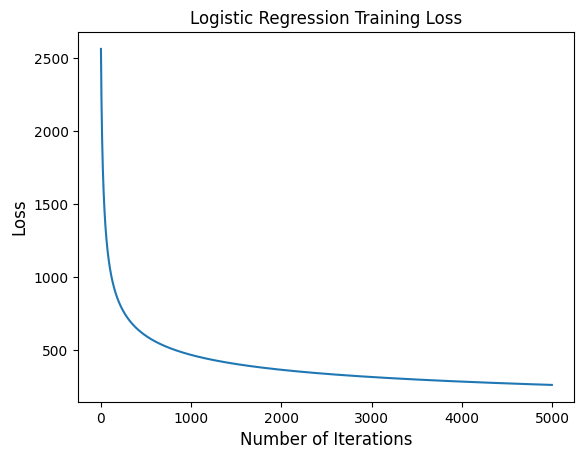

In [9]:
max_iter = 5000
alpha = 1e-5
final_w_spam, final_b_spam, losses = logistic_regression_grader(
    xTr, yTr, max_iter, alpha
)

# Compute training accuracy
scoresTr = y_pred_grader(xTr, final_w_spam, final_b_spam)
pred_labels = (scoresTr > 0.5).astype(int)
pred_labels[pred_labels != 1] = -1
training_acc = np.mean(pred_labels == yTr)

# Compute validation accuracy
scoresTe = y_pred_grader(xTe, final_w_spam, final_b_spam)
pred_labels = (scoresTe > 0.5).astype(int)
pred_labels[pred_labels != 1] = -1
validation_acc = np.mean(pred_labels == yTe)

print(f"Training Accuracy:   {100 * training_acc:.2f}%")
print(f"Validation Accuracy: {100 * validation_acc:.2f}%")

plt.figure()
plt.plot(losses)
plt.title("Logistic Regression Training Loss")
plt.xlabel("Number of Iterations", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.show()

## Scikit-Learn Approach

Scikit-learn actually provides two implementations of logistic regression: 

- [sklearn.linear_model.LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)

- [sklearn.linear_model.SGDClassifier(loss="log_loss")](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDClassifier.html)

The former uses second-order gradient methods (using the second derivative of negative log-likelihood) to converge faster. We will demonstrate using the latter implementation so that you get similar results to the classifier you built.

**NOTE:** The next cell may take a few minutes to run.

In [10]:
from sklearn.linear_model import SGDClassifier

regularizer_multiplier = 0.0
clf = SGDClassifier(
    loss="log_loss",               # Use log loss function
    tol=None,
    alpha=regularizer_multiplier,  # Don't use L2 or L1 regularizer
    learning_rate="constant",      # Constant learning rate
    eta0=alpha,
    max_iter=max_iter,             # Run to max_iter
)
clf.fit(xTr, yTr)
final_w_sklearn, final_b_sklearn = clf.coef_.flatten(), clf.intercept_.flatten()

# Compute training accuracy
scoresTr = y_pred_grader(xTr, final_w_sklearn, final_b_sklearn)
pred_labels = (scoresTr > 0.5).astype(int)
pred_labels[pred_labels != 1] = -1
training_acc_sklearn = np.mean(pred_labels == yTr)

# Compute validation accuracy
scoresTe = y_pred_grader(xTe, final_w_sklearn, final_b_sklearn)
pred_labels = (scoresTe > 0.5).astype(int)
pred_labels[pred_labels != 1] = -1
validation_acc_sklearn = np.mean(pred_labels == yTe)

print(f"Training Accuracy:   {100 * training_acc_sklearn:.2f}%")
print(f"Validation Accuracy: {100 * validation_acc_sklearn:.2f}%")

Training Accuracy:   97.90%
Validation Accuracy: 95.60%


## Challenge: Improve Your Spam Classifier [Ungraded]

You can improve your classifier in two ways, as described below.

1. **Feature Extraction**: Modify the function `extract_features_challenge`. This function takes in a `email` (list of lines in an email) and a feature dimension `B`, and should output a feature vector of dimension `B`. The autograder will pass in both arguments. We provide naive feature extraction from above as an example.

2. **Model Training**: Modify the function `train_spam_filter_challenge`. This function takes in training data `xTr, yTr` and should output a weight vector `w` and bias term `b` for classification. The predictions will be calculated exactly the same way as we have demonstrated in the previous cell. We provide an initial implementation using gradient descent and logistic regression.

Your model will be trained on the same training set above (loaded by `load_spam_data`), but we will test its accuracy on a testing dataset of emails (hidden from you).

In [18]:
feature_dimension = 512

def extract_features_challenge(email, B=feature_dimension):
    """
    Tokenize the email and hashes the symbols into a vector.
    Returns a vector representation for email; the vector is of length B.

    Input:
        email: List of lines in an email
        B: Number of dimensions of output vector

    Output:
        v: B-dimensional vector
    """
    import re
    
    v = np.zeros(B)          # Initialize all-zeros feature vector
    email = " ".join(email)  # Put email together from list of lines
    
    # Breaks for non-ascii characters
    tokens = email.split()
    for token in tokens:
        v[hash(token) % B] = 1

    # YOUR CODE HERE
    if "click" in email:
        v[hash("click")%B] = 1
    if "unsubscribe" in email:
        v[hash("UNSUBSCRIBE")%B]=1
    if "FREE" in email:
        v[hash("FREE")%B]=1
    if "transfer funds" in email.lower():
        v[hash("TRANSFER")%B]=1
    if "ADVERTISEMENT" in email:
        v[hash("ADVERTISEMENT")%B]=1    
    letters = [c for c in email if c.isalpha()]
    if letters: 
        upper_ratio = sum(c.isupper() for c in letters) / len(letters)
        if upper_ratio > 0.5:
            v[hash("MOSTLY_CAPS")%B] = 1
    # END OF YOUR CODE

    return v

In [19]:
def train_spam_filter_challenge(xTr, yTr):
    """
    Train a model on the data matrix xTr and label vector yTr.
    Return the optimal weight vector and bias term from training data.

    Input:
        xTr: Data matrix of shape (n, d)
        yTr: n-dimensional vector data labels (+1 or -1)

    Output:
        w, b
        w: d-dimension weight vector
        b: Scalar bias term
    """
    max_iter = 100
    alpha = 1e-5
    w, b, losses = logistic_regression_grader(xTr, yTr, max_iter, alpha)

    # YOUR CODE HERE
    max_iter = 1000
    alpha = 1e-4
    w, b, losses = logistic_regression_grader(xTr, yTr, max_iter, alpha)
    # END OF YOUR CODE
    
    return w, b


Run the next cell to check your implementation of `extract_features_challenge` and `train_spam_filter_challenge`.

**NOTE:** The next cell may take a few minutes to run.

In [20]:
def challenge_selftest():
    """
    Check your implementation of extract_features_challenge
    """
    
    # Load the training data
    xTr, yTr, cTr = load_spam_data(
        extract_features_challenge, feature_dimension, train_url
    )

    # Load the test data
    xTe, yTe, cTe = load_spam_data(
        extract_features_challenge, feature_dimension, test_url
    )

    # Train your spam email classifier
    w, b = train_spam_filter_challenge(xTr, yTr)

    # Calculate training accuracy
    scoresTr = sigmoid_grader(xTr @ w + b)
    preds_Tr = (scoresTr > 0.5).astype(int)
    preds_Tr[preds_Tr != 1] = -1
    training_accuracy = np.mean(preds_Tr == yTr)

    # Use trained classifier to get predictions
    scoresTe = sigmoid_grader(xTe @ w + b)
    preds = (scoresTe > 0.5).astype(int)
    preds[preds != 1] = -1

    # Calculate validation accuracy
    pos_ind = yTe == 1
    neg_ind = yTe == -1
    pos_acc = np.mean(yTe[pos_ind] == preds[pos_ind])
    neg_acc = np.mean(yTe[neg_ind] == preds[neg_ind])
    validation_accuracy = 0.5 * pos_acc + 0.5 * neg_acc

    return training_accuracy, validation_accuracy


training_acc_challenge, validation_acc_challenge = challenge_selftest()
print()
print("Your features and model achieved the following training and valication accuracy...")
print(f"Training accuracy:   {100 * training_acc_challenge:.2f}%")
print(f"Validation accuracy: {100 * validation_acc_challenge:.2f}%")

[########################################] | 100% Completed | 71.11 s
[########################################] | 100% Completed | 71.14 s
[########################################] | 100% Completed | 71.22 s
[########################################] | 100% Completed | 71.22 s
Loaded 5000 input emails.
[########################################] | 100% Completed | 18.32 s
[########################################] | 100% Completed | 18.35 s
[########################################] | 100% Completed | 18.37 s
[########################################] | 100% Completed | 18.39 s
[########################################] | 100% Completed | 18.44 s
Loaded 1034 input emails.

Your features and model achieved the following training and valication accuracy...
Training accuracy:   98.64%
Validation accuracy: 90.25%
